# 06 · First RL (GRPO) run

This notebook trains the SFT model further with **reinforcement learning**, using GRPO (group relative policy optimization). For each position, the model samples several answers. Stockfish scores each one with the reward from `04_dpo_rl_inputs.ipynb` (−1 for an illegal or unparseable answer; for a legal move, higher the closer it is to Stockfish's best). The model is then pushed towards the answers that scored above their group's average. No example answers are needed.

RL starts from the SFT model, and keeps training the same LoRA adapter with the settings in `configs/rl.yaml`.

Then it grades the RL model exactly as the other models, and compares all four: base, SFT, DPO, and RL.

**Before running:** run `03_sft_first_run.ipynb` (it creates `checkpoints/sft_v1/`) and, for the final comparison, `05_dpo_first_run.ipynb`.

**Outputs**
- the adapter in `checkpoints/grpo_v1/` (not on GitHub)
- the run logs `results/grpo_v1_training.json`, `results/grpo_v1_dev.json`, and `results/grpo_v1.json`
- figures in `results/figures/`
- the comparison table `results/progress_report_table.md`, now with all four models

In [1]:
# Settings
RUN_NAME = "grpo_v1"
PUZZLE_LIMIT = None   # None = all puzzles. Set a small number (e.g. 5) for a quick check.

import json

import pandas as pd
import torch

from chesslm.config import REPO_ROOT, load_config
from chesslm.engine import MoveScorer
from chesslm.evaluate import evaluate, load_eval_model, save_run, summarize

model_cfg = load_config("sft")["model"]
prompt_cfg = load_config("prompt")
eval_cfg = load_config("eval")
from chesslm import plots
from chesslm.rewards import to_rl_dataset
from chesslm.train_rl import train

rl_cfg = load_config("rl")
lora_cfg = load_config("sft")["lora"]
START_ADAPTER = REPO_ROOT / rl_cfg["training"]["start_adapter"]
ADAPTER_DIR = REPO_ROOT / "checkpoints" / RUN_NAME
FIGURES = REPO_ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def run_eval(model, tokenizer, split, run_name, adapter=None):
    """Grade the model on one puzzle set, save the results, and return the summary."""
    puzzles = pd.read_csv(REPO_ROOT / "data" / "eval" / f"puzzles_{split}.csv")
    if PUZZLE_LIMIT:
        puzzles = puzzles.head(PUZZLE_LIMIT)
    with MoveScorer(eval_cfg["stockfish"]) as scorer:
        graded = evaluate(model, tokenizer, puzzles, prompt_cfg, eval_cfg["generation"], scorer)
    summary = summarize(graded)
    config = {"model": model_cfg, "adapter": adapter, "prompt": prompt_cfg, "eval": eval_cfg, "split": split}
    save_run(run_name, graded, summary, config)
    print(f"{run_name}: {len(puzzles)} puzzles | accuracy {summary['puzzle_accuracy']:.1%} | "
          f"legal {summary['legal_rate']:.1%} | ACPL {summary['acpl'] if summary['acpl'] is not None else float('nan'):.0f} | "
          f"{summary['seconds_per_position']:.2f} s per puzzle")
    return graded, summary

W1103 03:23:29.678000 20668 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


## 1. Training positions

Positions from the training data (never from the test or dev puzzles), with the same prompts as SFT and evaluation. Each position also carries its FEN, which the reward uses to score the answers.

In [2]:
t = rl_cfg["training"]
train_positions = pd.read_parquet(REPO_ROOT / "data" / "processed" / "train.parquet")
train_ds = to_rl_dataset(train_positions.sample(n=t["num_positions"], random_state=t["seed"]), prompt_cfg)
print(f"{len(train_ds):,} positions x {t['num_generations']} answers each = "
      f"{len(train_ds) * t['num_generations']:,} answers scored by Stockfish\n")
print(train_ds[0]["prompt"][0]["content"])

2,000 positions x 8 answers each = 16,000 answers scored by Stockfish

Chess position (FEN): 6r1/1pp5/p3Pk1p/5P2/2p2K1N/P1P5/1P5P/6r1 w - - 3 35
White to move.
Reply with the best move in UCI notation (for example e2e4) and nothing else.


## 2. Training

The main thing to watch is the **average reward** of the sampled answers. It should rise as the model learns to avoid illegal moves and to pick moves closer to Stockfish's best.

Loading weights:   0%|          | 0/540 [00:00<?, ?it/s]

Step,Training Loss
10,0.000887
20,-0.000000
30,0.000000
40,-0.000000
50,0.000000
60,-0.000000
70,0.000000
80,0.000000
90,-0.000563
100,-0.000000


{
  "device": "NVIDIA GeForce RTX 5070 Ti Laptop GPU",
  "quantized_4bit": true,
  "wall_clock_minutes": 32.6,
  "gpu_hours": 0.543,
  "positions_seen": 2000,
  "answers_generated": 16000,
  "tokens_seen": 1504450
}

Average reward: -0.052 at the start -> 0.305 at the end


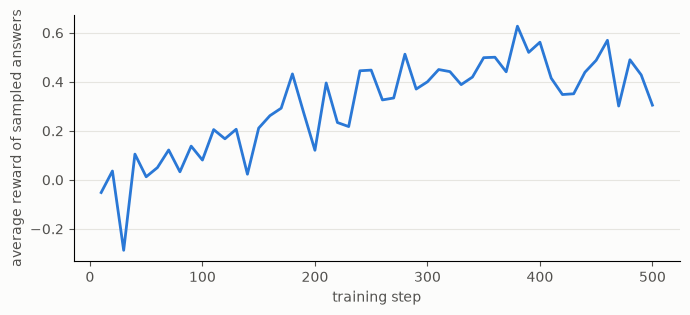

In [3]:
log, compute = train(train_ds, rl_cfg, eval_cfg["stockfish"], model_cfg, lora_cfg, START_ADAPTER, ADAPTER_DIR)

with open(REPO_ROOT / "results" / f"{RUN_NAME}_training.json", "w") as f:
    json.dump({"config": rl_cfg, "prompt": prompt_cfg, "start_adapter": str(START_ADAPTER), "compute": compute,
               "log": log.to_dict("records")}, f, indent=2, default=str)
print(json.dumps(compute, indent=2))

rewards = log.reward.dropna()
print(f"\nAverage reward: {rewards.iloc[0]:.3f} at the start -> {rewards.iloc[-1]:.3f} at the end")
plots.reward_curve(log, FIGURES / f"{RUN_NAME}_reward.png");

## 3. Grade the RL model

The same grading code, puzzles, and settings as every other model. Grading is greedy, even though training sampled answers.

In [4]:
import gc

gc.collect()  # free the memory used by training before loading the model for grading
torch.cuda.empty_cache()
tokenizer, model = load_eval_model(model_cfg, adapter_path=ADAPTER_DIR)
dev_graded, dev_summary = run_eval(model, tokenizer, "dev", f"{RUN_NAME}_dev", adapter=str(ADAPTER_DIR))
test_graded, test_summary = run_eval(model, tokenizer, "test", RUN_NAME, adapter=str(ADAPTER_DIR))

Loading weights:   0%|          | 0/540 [00:00<?, ?it/s]

grpo_v1_dev: 200 puzzles | accuracy 3.5% | legal 80.5% | ACPL 806 | 0.09 s per puzzle


grpo_v1: 1000 puzzles | accuracy 3.3% | legal 81.6% | ACPL 836 | 0.09 s per puzzle


## 4. Compare all four models

All numbers below are on the 1,000-puzzle test set. This table replaces the base vs. SFT table in `results/progress_report_table.md`.

In [5]:
summary = pd.read_csv(REPO_ROOT / "results" / "summary.csv")
runs = ["base", "sft_v1", "dpo_v1", RUN_NAME]
table = summary.set_index("run").loc[runs]

columns = {"puzzle_accuracy": "Accuracy", "accuracy_<1200": "<1200", "accuracy_1200-1800": "1200-1800",
           "accuracy_1800-2400": "1800-2400", "accuracy_2400+": "2400+", "legal_rate": "Legal",
           "illegal_rate": "Illegal", "unparseable_rate": "Unparseable", "acpl": "ACPL"}
report = table[list(columns)].rename(columns=columns)
percent = [c for c in report.columns if c != "ACPL"]
report[percent] = (report[percent] * 100).round(1)
report["ACPL"] = report["ACPL"].round(0)
report = report.astype(object).where(report.notna(), "–")  # e.g. ACPL when there are no legal moves

# Save as a Markdown table for the progress report (numbers only). Replaces the base vs. SFT table from notebook 03.
lines = ["| Model | " + " | ".join(report.columns) + " |", "|---" * (len(report.columns) + 1) + "|"]
lines += [f"| {run} | " + " | ".join(str(v) for v in row) + " |" for run, row in report.iterrows()]
note = "\n\nTest set: 1,000 Lichess puzzles (250 per rating band). Accuracy, legal, illegal, unparseable in %; ACPL in centipawns on legal moves."
(REPO_ROOT / "results" / "progress_report_table.md").write_text("\n".join(lines) + note + "\n")
report

,Accuracy,<1200,1200-1800,1800-2400,2400+,Legal,Illegal,Unparseable,ACPL
run,,,,,,,,,
base,2.8,2.4,4.8,2.4,1.6,41.2,45.8,13.0,828.0
sft_v1,7.8,8.4,8.4,10.8,3.6,72.2,27.8,0.0,793.0
dpo_v1,5.9,5.2,6.0,8.0,4.4,63.3,36.7,0.0,820.0
grpo_v1,3.3,3.2,0.8,6.0,3.2,81.6,18.4,0.0,836.0


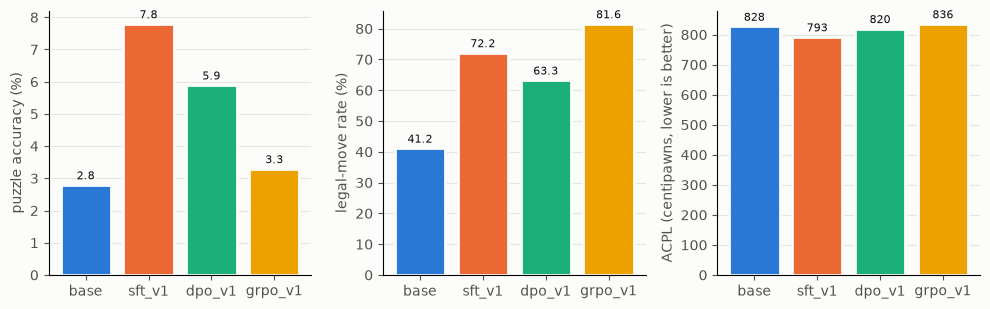

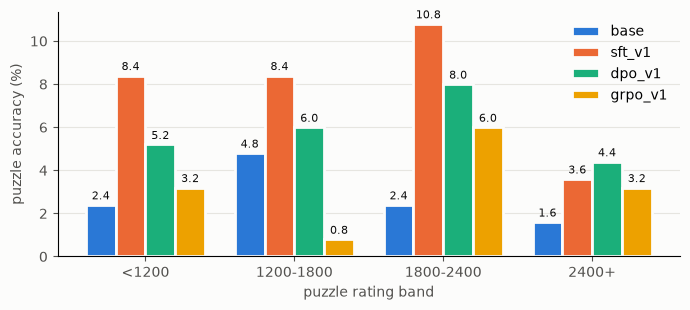

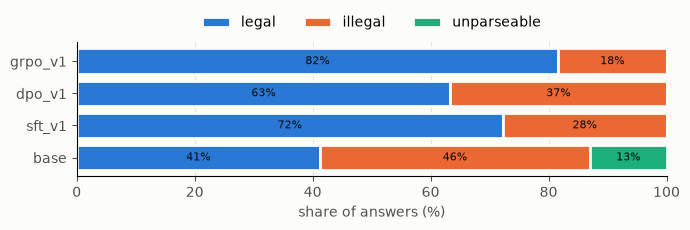

In [6]:
plots.compare_metrics(summary, runs, FIGURES / "all_runs_metrics.png");
plots.accuracy_by_band(summary, runs, FIGURES / "all_runs_accuracy_by_band.png");
plots.outcome_breakdown(summary, runs, FIGURES / "all_runs_answer_outcomes.png");

## Summary

The RL adapter is in `checkpoints/grpo_v1/`. The scores, training log, figures, and the four-model comparison table are in `results/`.

**After running:** push `results/` and `notebooks/` to GitHub (see the README), and share `checkpoints/dpo_v1/` and `checkpoints/grpo_v1/` with the team.